In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cvxpy as cvx
import skimage as ski
import skimage.io
import skimage.transform
from scipy.fft import dct,idct,dctn,idctn
import cv2
import time

Load in the image and down sample it so that CVXPY can solve the problem in a reasonable amount of time.

Original size:  (374, 266)
Rescaled size:  (37, 27)


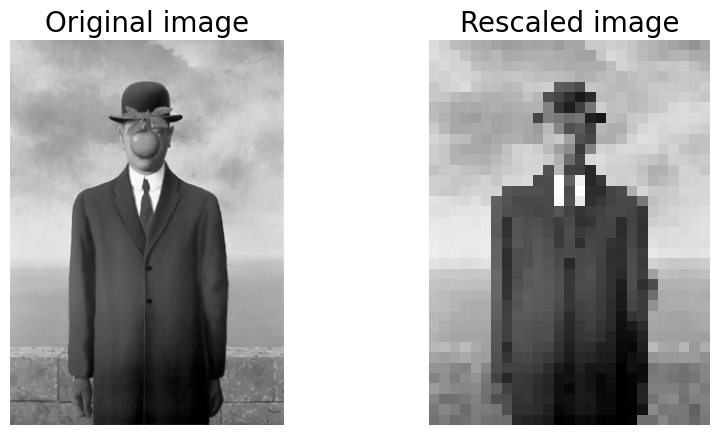

In [2]:
DOWNSAMPLE_RATE = 0.1
img_path = 'SonOfMan.jpg'
# read image
img_full = ski.io.imread(img_path)
# convert to grayscale and visualize 
img_full = ski.color.rgb2gray(img_full)
fig, ax = plt.subplots(1, 2, figsize=(10,5))
ax[0].imshow(img_full, cmap='gray')
ax[0].set_title("Original image", fontsize= 20)
ax[0].axis('off')
print("Original size: ", img_full.shape)
# resize image 
img = ski.transform.rescale(img_full, DOWNSAMPLE_RATE, anti_aliasing=False)
print("Rescaled size: ", img.shape)
ax[1].imshow(img, cmap='gray')
ax[1].set_title("Rescaled image", fontsize= 20)
ax[1].axis('off')
plt.show()

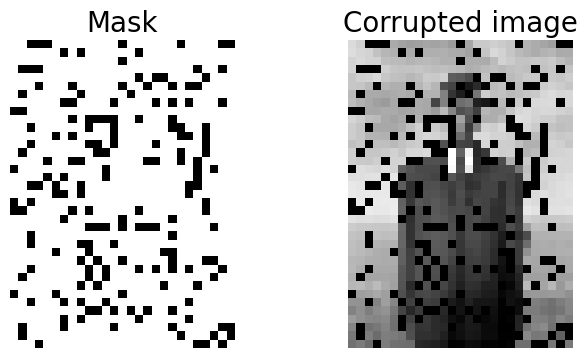

In [3]:
Ny, Nx = img.shape
mask_prop = 0.2
np.random.seed(515)
obs_indices = np.random.choice(Nx*Ny,int(mask_prop*Nx*Ny))
mask = np.ones(Ny*Nx)
mask[obs_indices]=0.
mask = mask.reshape(Ny,Nx)
masked_img = mask * img

fig, ax = plt.subplots(1,2 , figsize=(8, 4))
ax[0].imshow(mask, cmap = 'gray')
ax[0].set_title('Mask', fontsize= 20)
ax[0].axis('off')
ax[1].imshow(mask*img, cmap = 'gray')
ax[1].set_title('Corrupted image', fontsize= 20)
ax[1].axis('off')
plt.show()

In [4]:
def construct_DCT_Mat( Ny, Nx ):
  Dx = dct(np.eye(Nx), axis = 0, norm='ortho')
  Dy = dct(np.eye(Ny), axis = 0, norm='ortho')
  A = np.kron(Dy, Dx)
  return A
# construct inverse DCT matrix
def construct_iDCT_Mat( Ny, Nx ):
  Dx = idct(np.eye(Nx), axis = 0, norm='ortho')
  Dy = idct(np.eye(Ny), axis = 0, norm = 'ortho')
  invA = np.kron(Dy, Dx)
  return invA

# Dmask = ...
Ny, Nx = img.shape
dctMat = construct_DCT_Mat(Ny, Nx)
inv_dctMat = construct_iDCT_Mat(Ny, Nx)

In [5]:
def mse(mask, reconstruction, img):
    return np.mean(((1-mask)*(reconstruction - img))**2)/np.var(((1-mask)*img)**2)
    
def psnr(img, mse):
    if mse == 0:
        return float('inf')
    max_pixel = np.max(img)
    return 10 * np.log10((max_pixel ** 2) / mse)

## Compute the solution using CVXPY

Perform Task 2 in the Homework by writing down the "flattened" version of the optimization problem (2) and solve it using CVXPY. 

In [6]:
# implementing minimization using CVXPY
reg_lambda = 0.01
def optimize_cvx(mask, masked_img):
    x = cvx.Variable(Nx * Ny)
    err = 0.5 * cvx.sum_squares(np.diag(mask.flatten()) @ (inv_dctMat @ x - masked_img.flatten()))
    reg = reg_lambda * cvx.norm1(x)
    cvx.Problem(cvx.Minimize(err + reg)).solve()
    return x.value

## Evaluate the reconstruction here
We calculate mean squared error on the masked out pixels relative to the variance on the original image. Report these values in your report. 

Execution time: 2.6940 seconds
Mean squared error: 0.047923283929322893
PSNR: 12.805031123986835


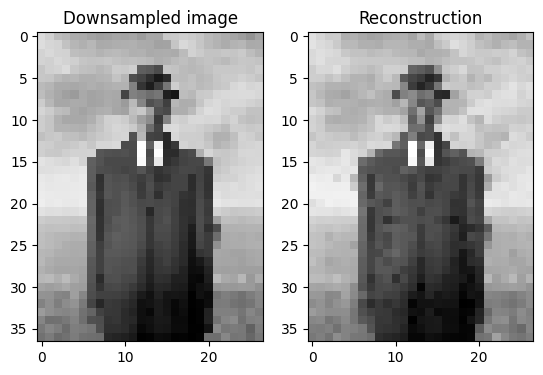

In [7]:
start_time = time.perf_counter()
sol = optimize_cvx(mask, masked_img)
end_time = time.perf_counter()
execution_time = end_time - start_time
print(f"Execution time: {execution_time:.4f} seconds")

reconstruction = idctn(sol.reshape(Ny,Nx),norm = 'ortho')

relative_mse = mse(mask, reconstruction, img)
print("Mean squared error:", relative_mse)
print("PSNR:", psnr(img, relative_mse))

plt.subplot(1,2,1)
plt.imshow(img,cmap = 'gray')
plt.title("Downsampled image")
plt.subplot(1,2,2)
plt.imshow(reconstruction,cmap ='gray')
plt.title("Reconstruction")
plt.show()

Side note, unrelated to your HW: 

using CVXPY this way is really not a great idea since:
1. We're materializing DCT matrices, which makes calculations expensive. 
2. We're instantiating (large+dense) Kronecker product matrices, these are precisely the A and invA matrices. 

Often, however, for smaller problems (and much harder problems), CVXPY can work incredibly well!
We downsampled the problem a lot so that it'll run quickly, but if you try increasing the resolution by a bit, it'll start taking much much longer. For example, try increasing the DOWNSAMPLE_RATE to 0.2 and you'll see cvxpy slows down a lot. 

Again, You don't need to report this in your report. 

## Implement your own Proximal Gradient Descent

In order to write a fast implementation, you should avoid instantiating matrices whenever possible and just apply the DCT and iDCT functions from Scipy, i.e., scipy.fft.dctn and scipy.fft.idctn may be useful!

In [8]:
def build_objective_components(mask,masked_image,lam):
    def f(x):
        idct_x = idctn(x,norm = 'ortho')
        f_x = 0.5 * np.sum((mask * (idct_x - masked_image)) ** 2)
        return f_x

    def gradf(x):
        idct_x = idctn(x, norm = 'ortho')
        grad = dctn(mask * (idct_x - masked_image), norm = 'ortho')
        return grad

    def L1(x):
        return lam * np.sum(np.abs(x))

    def proxL1(x,t):
        return np.sign(x) * np.maximum(np.abs(x) - t * lam, 0)
    
    return f, gradf, L1, proxL1

def PGD_solve(x0, f, gradf, h, proxh, max_iter =50000, tol = 1e-4):
    i = 0
    alpha = 0.5
    x_curr = x0
    while i < max_iter:
        x_next = proxh(x_curr - alpha * gradf(x_curr), alpha)
        if np.linalg.norm(x_next - x_curr) <= tol and np.abs(f(x_next) - f(x_curr)) <= tol:
            print(f"converged in {i} steps")
            return x_next
        x_curr = x_next
        i = i + 1
    print("did not converge")
    return None

First apply your code to the down sampled image and compare to the CVXPY solution to make sure it is working. Report the relative MSE as before.

converged in 501 steps
Execution time: 0.0424 seconds
Mean squared error: 0.047981308130400274
PSNR: 12.799775985963034


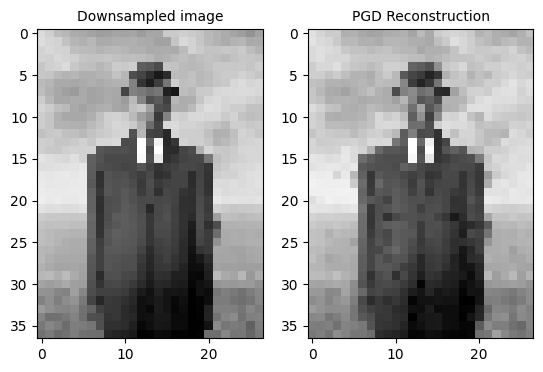

In [9]:
f,gradf,L1,proxL1 = build_objective_components(mask, masked_img, 0.01)
x0 = dctn(masked_img, norm='ortho')

start_time = time.perf_counter()
sol_pgd = PGD_solve(x0, f,gradf,L1,proxL1)
end_time = time.perf_counter()
execution_time = end_time - start_time
print(f"Execution time: {execution_time:.4f} seconds")

reconstruction = idctn(sol_pgd, norm = 'ortho')

relative_mse = mse(mask, reconstruction, img)
print("Mean squared error:", relative_mse)
print("PSNR:", psnr(img, relative_mse))

plt.subplot(1,2,1)
plt.imshow(img,cmap = 'gray')
plt.title("Downsampled image", fontsize= 10)
plt.subplot(1,2,2)
plt.imshow(reconstruction,cmap ='gray')
plt.title("PGD Reconstruction", fontsize= 10)
plt.show()

## Now rerun on the full size image with more masking
This should still be pretty fast if you implemented the PGD correctly using the scipy functions. 

Rescaled size:  (374, 266)


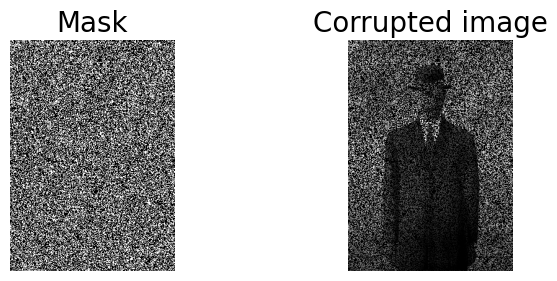

In [10]:
# resize image 
img = ski.transform.rescale(img_full, 1., anti_aliasing=False)
Ny, Nx = img.shape
mask_prop = 0.6
mask_indices = np.random.choice(Nx*Ny,int(mask_prop*Nx*Ny),replace = False)
mask = np.ones(Ny*Nx)
mask[mask_indices]=0.
mask = mask.reshape(Ny,Nx)
masked_img = mask * img
print("Rescaled size: ", img.shape)

ax[1].imshow(img, cmap='gray')
ax[1].set_title("Rescaled image", fontsize= 20)
ax[1].axis('off')
plt.show()

fig, ax = plt.subplots(1,2 , figsize=(8, 3))
ax[0].imshow(mask, cmap = 'gray')
ax[0].set_title('Mask', fontsize= 20)
ax[0].axis('off')
ax[1].imshow(mask*img, cmap = 'gray')
ax[1].set_title('Corrupted image', fontsize= 20)
ax[1].axis('off')
plt.show()

Present a figure comparing the original, corrupted, and recovered images using your algorithm. Also compute the relative MSE of the recovered image and include it in the report. 

converged in 658 steps
Execution time: 1.1383 seconds
Mean squared error: 0.009276689542062901
PSNR: 20.23281932302139


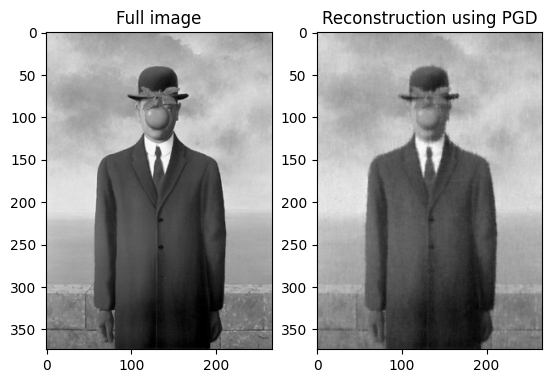

In [11]:
f,gradf,L1,proxL1 = build_objective_components(mask, masked_img, 0.01)
x0 = dctn(masked_img, norm='ortho')

start_time = time.perf_counter()
sol_pgd = PGD_solve(x0, f,gradf,L1,proxL1)
end_time = time.perf_counter()
execution_time = end_time - start_time
print(f"Execution time: {execution_time:.4f} seconds")

reconstruction = idctn(sol_pgd, norm = 'ortho')

relative_mse = mse(mask, reconstruction, img)
print("Mean squared error:", relative_mse)
print("PSNR:", psnr(img, relative_mse))

plt.subplot(1,2,1)
plt.imshow(img,cmap = 'gray')
plt.title("Full image")
plt.subplot(1,2,2)
plt.imshow(reconstruction,cmap ='gray')
plt.title("Reconstruction using PGD")
plt.show()

Below is an implementation of Fast Iterative Shrinkage-Threshold Algorithm (FISTA).
It improves upon PGD by not relying only on the last iterate, but mixes past iterates.
This is referred to as momentum and it helps accelerate convergence.

Mean squared error: 0.009276689542062901
PSNR: 20.23281932302139
converged in 329 steps
Execution time: 0.5751 seconds


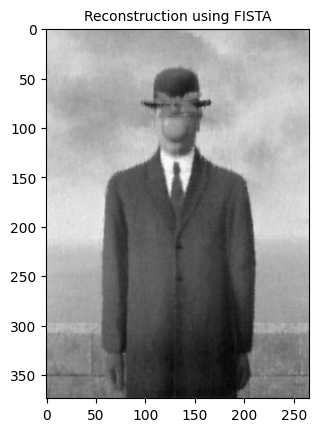

In [12]:
def soft_threshold(x, threshold):
    return np.sign(x) * np.maximum(np.abs(x) - threshold, 0)

def fista_recovery(img, mask, reg_lambda=0.01, max_iter=1000, tol=1e-4):
    Ny, Nx = img.shape
    img_dct = dctn(img, norm='ortho')
    x = np.zeros((Ny, Nx))
    y = np.copy(x)
    t = 1.0
    alpha = 1.0
    for k in range(max_iter):
        idct_y = idctn(y, norm='ortho')
        gradient = dctn(mask * (idct_y - img), norm='ortho')
        x_new = soft_threshold(y - alpha * gradient, reg_lambda * alpha)
        t_new = (1 + np.sqrt(1 + 4 * t ** 2)) / 2
        y = x_new + ((t - 1) / t_new) * (x_new - x)
        if np.linalg.norm(x_new - x) < tol:
            print(f"converged in {k} steps")
            break
        x, t = x_new, t_new
    return idctn(x, norm='ortho')

relative_mse = mse(mask, reconstruction, img)
print("Mean squared error:", relative_mse)
print("PSNR:", psnr(img, relative_mse))

start_time = time.perf_counter()
recovered_img = fista_recovery(masked_img, mask)
end_time = time.perf_counter()
execution_time = end_time - start_time
print(f"Execution time: {execution_time:.4f} seconds")

plt.imshow(recovered_img, cmap ='gray')
plt.title("Reconstruction using FISTA", fontsize=10)
plt.show()